# 02. Бейзлайны

Эксперименты 1–3 для двух таргетов, `points` и `log(price)`:

1. **Предсказание средним**: нижняя планка, R² = 0 по определению
2. **Только метаданные + CatBoost**: сколько дают страна, регион, сорт, винодельня и дегустатор без текста
3. **TF-IDF + Ridge**: классический текстовый бейзлайн, без метаданных

Протокол для всех ноутбуков: модель обучается на train, гиперпараметры и early stopping подбираются по val,
test используется один раз для финальных метрик в `results/metrics.csv`.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import TEXT_COL, POINTS_COL, LOG_PRICE_COL, META_COLS
from src.split import load_splits
from src.metrics import regression_metrics, log_metrics, save_predictions, results_table
from src.models import meta_features, fit_catboost, tfidf_vectorizer, fit_ridge
from src.plots import set_style, save, MAIN, PALETTE, TEXT_MUTED

set_style()
train, val, test = load_splits()
TARGETS = [POINTS_COL, LOG_PRICE_COL]
print(f"train {len(train):,}, val {len(val):,}, test {len(test):,}")

train 89,253, val 11,157, test 11,157


In [2]:
def evaluate(experiment, target, y_pred):
    """Метрики на test: пишет их в metrics.csv, сохраняет предсказания и возвращает dict."""
    y_true = test[target]
    m = regression_metrics(y_true, y_pred)
    log_metrics(experiment, target, m)
    save_predictions(experiment, target, test.index, y_true, y_pred)
    return m

summary = {}

## 1. Предсказание средним

Среднее берём по train. На test R² будет чуть ниже нуля, потому что среднее test немного отличается от среднего train.

In [3]:
for t in TARGETS:
    pred = np.full(len(test), train[t].mean())
    summary[("mean", t)] = evaluate("mean", t, pred)
pd.DataFrame(summary).T.round(3)

RMSE    MAE   R2
mean points     3.100  2.539 -0.0
     log_price  0.659  0.527 -0.0

## 2. Только метаданные + CatBoost

Признаки: `country`, `province`, `region_1`, `variety`, `winery`, `taster_name`.
Все категориальные, пропуск становится отдельной категорией `NA`. CatBoost кодирует категории через упорядоченные
target statistics, поэтому `winery` с 15 тыс. значений можно подавать как есть, без one-hot.

In [4]:
X_tr, X_va, X_te = (meta_features(d) for d in (train, val, test))
cb_models = {}
for t in TARGETS:
    t0 = time.time()
    model = fit_catboost(X_tr, train[t], X_va, val[t], cat_features=META_COLS)
    cb_models[t] = model
    summary[("meta_catboost", t)] = evaluate("meta_catboost", t, model.predict(X_te))
    print(f"{t}: лучшая итерация {model.get_best_iteration()}, {time.time() - t0:.0f} с")
pd.DataFrame(summary).T.round(3)

points: лучшая итерация 3063, 66 с


log_price: лучшая итерация 6992, 147 с


RMSE    MAE     R2
mean          points     3.100  2.539 -0.000
              log_price  0.659  0.527 -0.000
meta_catboost points     2.207  1.739  0.493
              log_price  0.378  0.275  0.672

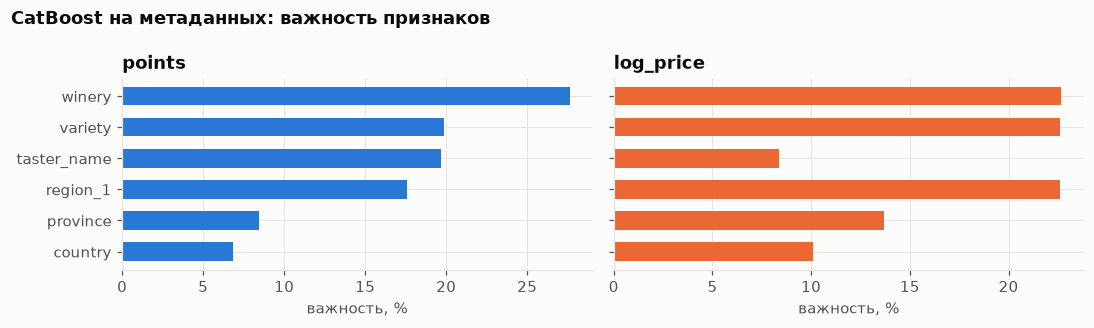

In [5]:
imp = pd.DataFrame({t: cb_models[t].get_feature_importance(prettified=True).set_index("Feature Id")["Importances"]
                    for t in TARGETS}).loc[META_COLS]
imp = imp.sort_values(POINTS_COL)

fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, t, c in zip(axes, TARGETS, (MAIN, PALETTE[1])):
    ax.barh(imp.index, imp[t], color=c, height=0.6)
    ax.set_title(t)
    ax.set_xlabel("важность, %")
fig.suptitle("CatBoost на метаданных: важность признаков", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "baseline_meta_importance")
plt.show()

## 3. TF-IDF + Ridge

Слова и биграммы, `min_df=3`, `sublinear_tf`. Векторайзер обучается только на train, один раз для обоих таргетов.
`alpha` у Ridge подбираем по RMSE на val.

In [6]:
t0 = time.time()
vec = tfidf_vectorizer()
T_tr = vec.fit_transform(train[TEXT_COL])
T_va, T_te = vec.transform(val[TEXT_COL]), vec.transform(test[TEXT_COL])
print(f"словарь: {T_tr.shape[1]:,} признаков, {time.time() - t0:.0f} с")

ridge_models, alpha_curves = {}, {}
for t in TARGETS:
    model, curve = fit_ridge(T_tr, train[t], T_va, val[t], alphas=(0.3, 1, 2, 3, 5, 10, 30))
    ridge_models[t], alpha_curves[t] = model, curve
    summary[("tfidf_ridge", t)] = evaluate("tfidf_ridge", t, model.predict(T_te))
    print(f"{t}: alpha = {model.alpha}")
display(pd.DataFrame(alpha_curves).round(4))
pd.DataFrame(summary).T.round(3)

словарь: 135,778 признаков, 4 с


points: alpha = 1


log_price: alpha = 2


,points,log_price
alpha,,
0.3,1.7175,0.4987
1.0,1.6646,0.4734
2.0,1.6808,0.4697
3.0,1.7048,0.4706
5.0,1.7500,0.4745
10.0,1.8384,0.4840
30.0,2.0531,0.5089


RMSE    MAE     R2
mean          points     3.100  2.539 -0.000
              log_price  0.659  0.527 -0.000
meta_catboost points     2.207  1.739  0.493
              log_price  0.378  0.275  0.672
tfidf_ridge   points     1.662  1.309  0.713
              log_price  0.474  0.363  0.483

Самые сильные слова и биграммы по коэффициентам Ridge среди n-грамм, которые встречаются минимум в 200 отзывах train:
без этого порога топ забивают редкие n-граммы.

n-грамм с частотой >= 200: 3,603

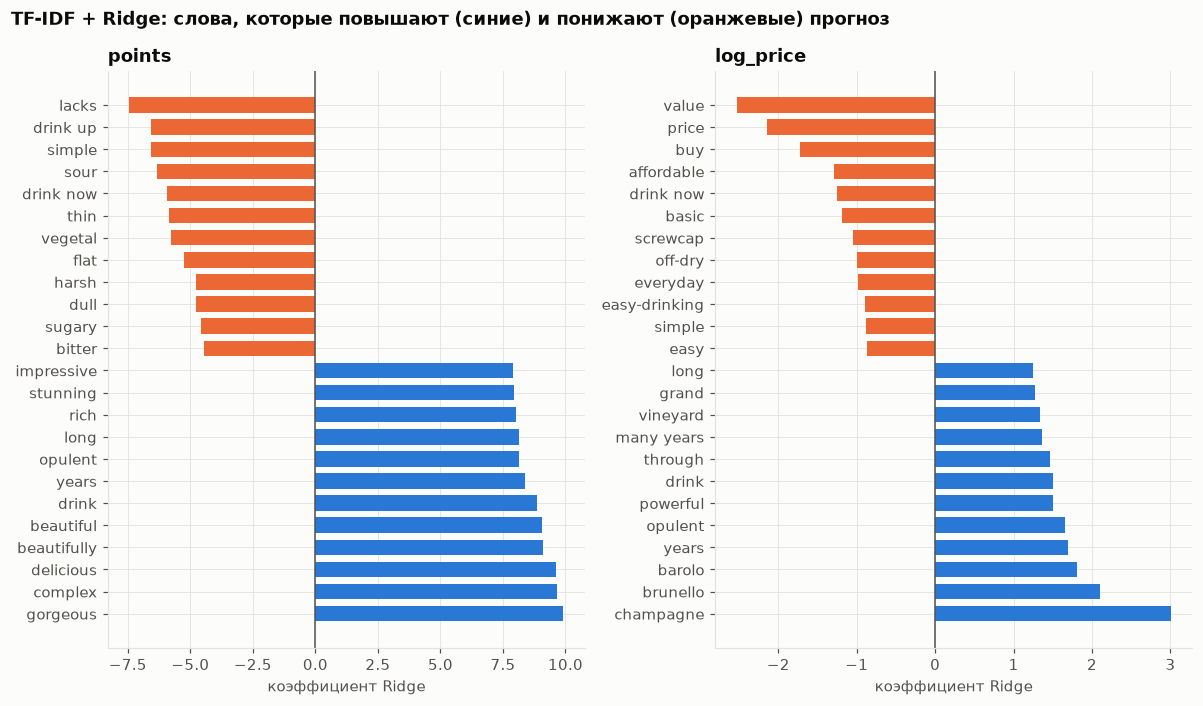

In [7]:
vocab = np.array(vec.get_feature_names_out())
doc_freq = np.asarray((T_tr > 0).sum(0)).ravel()
frequent = doc_freq >= 200
print(f"n-грамм с частотой >= 200: {frequent.sum():,}")

fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
for ax, t in zip(axes, TARGETS):
    coef = pd.Series(ridge_models[t].coef_[frequent], index=vocab[frequent])
    w = pd.concat([coef.nsmallest(12), coef.nlargest(12).iloc[::-1]])
    ax.barh(w.index, w.values, color=[MAIN if v > 0 else PALETTE[1] for v in w.values], height=0.7)
    ax.axvline(0, color=TEXT_MUTED, lw=1)
    ax.invert_yaxis()
    ax.set_title(t)
    ax.set_xlabel("коэффициент Ridge")
fig.suptitle("TF-IDF + Ridge: слова, которые повышают (синие) и понижают (оранжевые) прогноз",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "baseline_tfidf_coefs")
plt.show()

## 4. Сводка

In [8]:
for t in TARGETS:
    print(t)
    display(results_table(t).loc[["mean", "meta_catboost", "tfidf_ridge"], ["RMSE", "MAE", "R2"]].round(3))

points


metric,RMSE,MAE,R2
experiment,,,
mean,3.100,2.539,-0.000
meta_catboost,2.207,1.739,0.493
tfidf_ridge,1.662,1.309,0.713


log_price


metric,RMSE,MAE,R2
experiment,,,
mean,0.659,0.527,-0.000
meta_catboost,0.378,0.275,0.672
tfidf_ridge,0.474,0.363,0.483


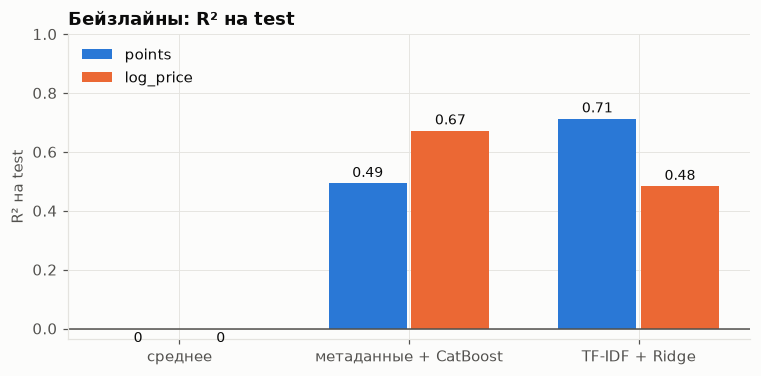

In [9]:
exps = ["mean", "meta_catboost", "tfidf_ridge"]
labels = ["среднее", "метаданные + CatBoost", "TF-IDF + Ridge"]
x = np.arange(len(exps))

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, (t, c) in enumerate(zip(TARGETS, (MAIN, PALETTE[1]))):
    r2 = [summary[(e, t)]["R2"] for e in exps]
    bars = ax.bar(x + (i - 0.5) * 0.36, r2, width=0.34, color=c, label=t)
    ax.bar_label(bars, labels=[f"{v:.2f}" if abs(v) >= 0.005 else "0" for v in r2], padding=2, fontsize=9)
ax.set_xticks(x, labels)
ax.set_ylabel("R² на test")
ax.set_ylim(min(0, ax.get_ylim()[0]), 1)
ax.axhline(0, color=TEXT_MUTED, lw=1)
ax.set_title("Бейзлайны: R² на test")
ax.legend(loc="upper left")
save(fig, "baseline_r2")
plt.show()

## 5. Выводы

| | points RMSE | points R² | log(price) MAE | log(price) R² |
|---|---|---|---|---|
| среднее | 3.10 | 0.00 | 0.527 | 0.00 |
| метаданные + CatBoost | 2.21 | 0.49 | 0.275 | **0.67** |
| TF-IDF + Ridge | **1.66** | **0.71** | 0.363 | 0.48 |

**Оценку лучше предсказывает текст, цену лучше предсказывают метаданные.**
- Для `points` простой TF-IDF + Ridge уже объясняет 71% дисперсии, RMSE 1.66 против 3.10 у среднего. Метаданные без текста дают 0.49.
- Для `log(price)` всё наоборот: метаданные дают R² = 0.67, текст 0.48. Это совпадает с EDA, где eta² у `region_1` и `variety` для цены был в 2 раза выше, чем для оценки. Цена во многом определяется происхождением (апелласьон, винодельня), а не вкусом.
- Отсюда ожидание для экспериментов 4 и 6: добавление метаданных к тексту немного улучшит оценку и сильно улучшит цену.

**Метаданные для оценки работают за счёт `winery` и `taster_name`.** Винодельня несёт «репутацию» (средний уровень вин производителя),
дегустатор вносит личное смещение, примерно 4 балла между дегустаторами (см. EDA). У цены важность распределена между `winery`, `variety` и `region_1`.

**Что выучил Ridge.**
- Для оценки это оценочная лексика: *gorgeous, complex, delicious, stunning* против *lacks, simple, thin, dull, sour*.
  Плюс сигнал потенциала выдержки: *years* повышает прогноз, а *drink now / drink up* понижает (вино для немедленного потребления).
- Для цены модель находит в тексте метаданные: *champagne, brunello, barolo, grand (cru), vineyard* повышают прогноз,
  а слова про доступность (*value, price, buy, affordable, everyday, screwcap*) понижают. Сомелье часто прямо пишут о соотношении цены и качества.

**Ориентиры для следующих этапов:** RMSE 1.66 / R² 0.71 по оценке и R² 0.67 по цене. Эмбеддинги и RoBERTa должны их превзойти.